# Chapitre 2 - Exercices 2.7 à 2.12

Ce notebook propose six exercices corrigés sur la seconde moitié du chapitre 2
(post-entraînement et échantillonnage) :

- **2.7** : classer des modèles à partir de duels avec Bradley-Terry (façon Chatbot
  Arena), et le piège du taux de victoire ;
- **2.8** : démontrer que l'entropie croît avec la température, et le vérifier sur de
  vrais logits ;
- **2.9** : implémenter le top-p soi-même, le tester, et comparer au top-k sur un vrai
  modèle ;
- **2.10** : le vote majoritaire (*self-consistency*), de la théorie de Condorcet à un
  vrai modèle ;
- **2.11** : écrire un décodage contraint par arbre de préfixes pour router des
  messages, puis forcer un format de date ;
- **2.12** : logprob d'une séquence, sous-dépassement et biais de longueur.

In [1]:
import warnings
from math import comb

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from aie import llm
from aie import ch02_modeles as m
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT,
                          annotate_bars, subtitle, finish)

set_style()
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
llm.seed_everything(0)
rng = np.random.default_rng(0)
pd.set_option("display.max_colwidth", 90)
BASE_QWEN = "Qwen/Qwen2.5-0.5B"
tok, model = llm.load(llm.SMALL)


def short(txt, n=90):
    txt = " ".join(str(txt).split())
    return txt if len(txt) <= n else txt[:n] + " [...]"

## Exercice 2.7 : Classer des modèles à partir de duels

**Énoncé.** Une plateforme fait voter des utilisateurs entre les réponses de deux modèles
anonymes (comme Chatbot Arena, chapitre 4). Six modèles A à F ont des forces latentes
$s = (1{,}2 ;\ 0{,}8 ;\ 0{,}5 ;\ 0 ;\ -0{,}4 ;\ -1)$ et
$P(i \text{ bat } j) = \sigma(s_i - s_j)$. Les appariements ne sont **pas** uniformes : le
modèle D, nouveau venu, a surtout affronté les modèles les plus faibles.

1. Simuler 4 000 duels, puis calculer le **taux de victoire** de chaque modèle. Le
   classement obtenu est-il correct ?
2. Ajuster un modèle de Bradley-Terry (`m.fit_bradley_terry`) et comparer.
3. Convertir les forces en score de type Elo ($R = 1000 + \frac{400}{\ln 10}\,s$) et
   estimer leur incertitude par *bootstrap*.

**Rappels.** Section *Reward model* : le modèle de Bradley-Terry suppose
$P(y_w \succ y_l) = \sigma(r_w - r_l)$ et s'ajuste en minimisant $-\log\sigma(r_w - r_l)$
(cours 3, section 4). Seules les différences de scores sont identifiables.

**Solution.**

1. Le taux de victoire dépend des **adversaires rencontrés** : un modèle moyen qui affronte
   surtout des faibles gagne souvent. Le classement par taux de victoire peut donc placer
   D devant des modèles plus forts que lui.
2. Bradley-Terry modélise chaque duel en tenant compte de la force de l'adversaire : battre
   un faible rapporte peu, battre un fort beaucoup. Il retrouve l'ordre latent.
3. Le facteur $400/\ln 10 \approx 173{,}7$ fait correspondre une différence de 400 points à
   une probabilité de victoire de $1/(1+10^{-1}) \approx 91\,\%$, comme aux échecs.

In [2]:
names = list("ABCDEF")
s_true = np.array([1.2, 0.8, 0.5, 0.0, -0.4, -1.0])
W, L, pair_list = [], [], []
for _ in range(4000):
    if rng.random() < 0.35:                         # D joue surtout contre E et F
        i, j = 3, rng.choice([4, 5])
    else:
        i, j = rng.choice(6, 2, replace=False)
    win_i = rng.random() < m.sigmoid(s_true[i] - s_true[j])
    W.append(i if win_i else j); L.append(j if win_i else i)
W, L = np.array(W), np.array(L)
games = np.bincount(W, minlength=6) + np.bincount(L, minlength=6)
winrate = np.bincount(W, minlength=6) / games
s_hat, hist = m.fit_bradley_terry(W, L, 6)
elo = 1000 + 400 / np.log(10) * s_hat
boot = []
for _ in range(100):
    idx = rng.integers(0, len(W), len(W))
    sb, _ = m.fit_bradley_terry(W[idx], L[idx], 6, epochs=300)
    boot.append(1000 + 400 / np.log(10) * sb)
boot = np.array(boot)
res = pd.DataFrame({"force latente": s_true, "duels joués": games, "taux de victoire": winrate,
                    "rang (taux)": (-winrate).argsort().argsort() + 1, "Elo (BT)": elo,
                    "IC 95 % Elo": [f"[{lo:.0f}, {hi:.0f}]" for lo, hi in np.percentile(boot, [2.5, 97.5], axis=0).T],
                    "rang (BT)": (-s_hat).argsort().argsort() + 1}, index=names)
res.round(2)

,force latente,duels joués,taux de victoire,rang (taux),Elo (BT),IC 95 % Elo,rang (BT)
A,1.2,901,0.78,1,1186.27,"[1167, 1208]",1
B,0.8,877,0.65,2,1101.26,"[1077, 1118]",2
C,0.5,875,0.58,3,1056.61,"[1034, 1079]",3
D,0.0,2228,0.58,4,966.06,"[954, 981]",4
E,-0.4,1608,0.36,5,891.93,"[878, 908]",5
F,-1.0,1511,0.24,6,797.86,"[780, 812]",6


**Vérification graphique.**

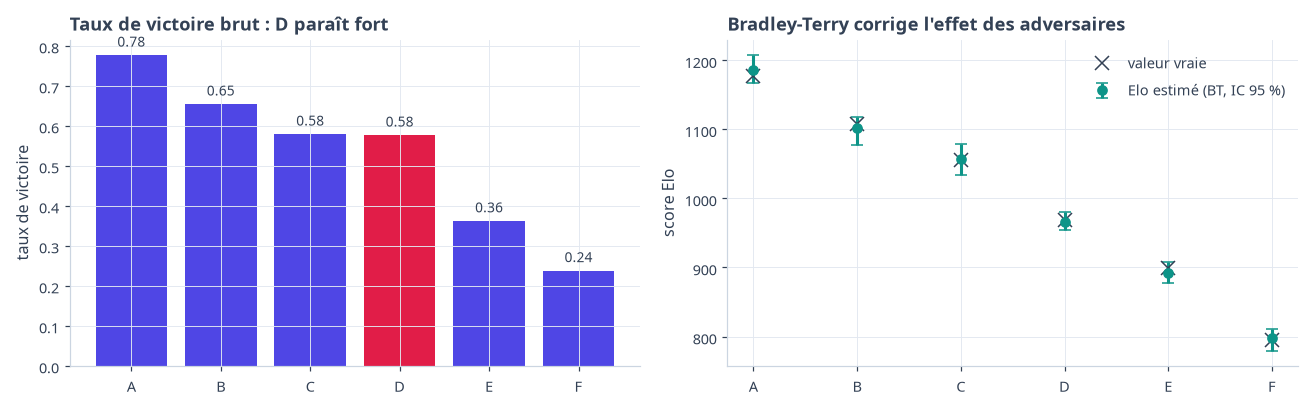

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(names, winrate, color=[ROSE if n == "D" else INDIGO for n in names])
annotate_bars(axes[0], "{:.2f}"); axes[0].set_ylabel("taux de victoire")
axes[0].set_title("Taux de victoire brut : D paraît fort")
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
axes[1].errorbar(names, elo, yerr=[elo - lo, hi - elo], fmt="o", color=TEAL, capsize=4, label="Elo estimé (BT, IC 95 %)")
axes[1].plot(names, 1000 + 400 / np.log(10) * (s_true - s_true.mean()), "x", color=SLATE, ms=9, label="valeur vraie")
axes[1].set_ylabel("score Elo"); axes[1].legend(); axes[1].set_title("Bradley-Terry corrige l'effet des adversaires")
plt.tight_layout(); plt.show()

Le taux de victoire de D est gonflé par ses adversaires faibles ; Bradley-Terry le remet à
sa place (quatrième), avec des intervalles de confiance étroits grâce aux 4 000 duels.
C'est le même modèle que celui des modèles de récompense : ici, les « réponses » sont des
modèles entiers.

> **À retenir.** Ne classez jamais par taux de victoire brut quand les appariements ne
> sont pas équilibrés : Bradley-Terry (ou Elo) tient compte de la force des adversaires.

## Exercice 2.8 : Température et entropie

**Énoncé.** Soit $p_i(T) = e^{x_i/T} / Z(T)$ avec $Z(T) = \sum_j e^{x_j/T}$, et
$H(T) = -\sum_i p_i \log p_i$.

1. Montrer que $\dfrac{dH}{dT} = \dfrac{\operatorname{Var}_{p(T)}(x)}{T^3} \ge 0$.
2. Déterminer les limites de $H$ quand $T \to 0^+$ et $T \to +\infty$.
3. Vérifier la formule par différences finies sur les vrais logits de Qwen2.5-0.5B, et
   mesurer l'effet de la température sur la diversité (nombre de tokens distincts parmi
   300 tirages).

**Rappels.** Section *Temperature* : la température divise les logits avant la softmax ;
l'entropie mesure l'incertitude d'une distribution (cours 4, section 2).

**Solution.**

1. Posons $\beta = 1/T$. Alors $\log p_i = \beta x_i - \log Z$ et
   $H = -\sum_i p_i(\beta x_i - \log Z) = \log Z - \beta\,\mathbb E_p[x]$.
   Résultats classiques (famille exponentielle) : $\frac{d\log Z}{d\beta} = \mathbb E_p[x]$ et
   $\frac{d\,\mathbb E_p[x]}{d\beta} = \operatorname{Var}_p(x)$. D'où
   $\frac{dH}{d\beta} = \mathbb E_p[x] - \mathbb E_p[x] - \beta\operatorname{Var}_p(x) = -\beta\operatorname{Var}_p(x)$,
   puis, avec $\frac{d\beta}{dT} = -\frac{1}{T^2}$ :
   $$\frac{dH}{dT} = \beta \operatorname{Var}_p(x)\,\frac{1}{T^2} = \frac{\operatorname{Var}_p(x)}{T^3} \ge 0. \qquad\blacksquare$$
   L'entropie est strictement croissante dès que les logits ne sont pas tous égaux.
2. Quand $T \to 0^+$, la masse se concentre sur les $m$ tokens de logit maximal :
   $H \to \log m$ (0 si le maximum est unique : décodage glouton). Quand $T \to \infty$,
   $x_i/T \to 0$ et $p$ tend vers l'uniforme : $H \to \log V$.

In [4]:
z = llm.full_logits("Le week-end prochain, nous irons", BASE_QWEN)
Ts = np.logspace(-1, 0.7, 30)
H = np.array([m.entropy(llm.softmax(z, t)) for t in Ts])
eps = 1e-4
dH_num = np.array([(m.entropy(llm.softmax(z, t + eps)) - m.entropy(llm.softmax(z, t - eps))) / (2 * eps) for t in Ts])
dH_th = []
for t in Ts:
    p = llm.softmax(z, t)
    mu = (p * z).sum()
    dH_th.append((p * (z - mu) ** 2).sum() / t ** 3)
dH_th = np.array(dH_th)
print(f"écart relatif max. entre dérivée numérique et formule : {np.max(np.abs(dH_num - dH_th) / dH_th):.1e}")
print(f"H(T=0.1) = {H[0]:.3f} nats ; log V = {np.log(len(z)):.2f} nats")

écart relatif max. entre dérivée numérique et formule : 3.2e-07
H(T=0.1) = 0.269 nats ; log V = 11.93 nats


**Vérification graphique** (formule et diversité des tirages).

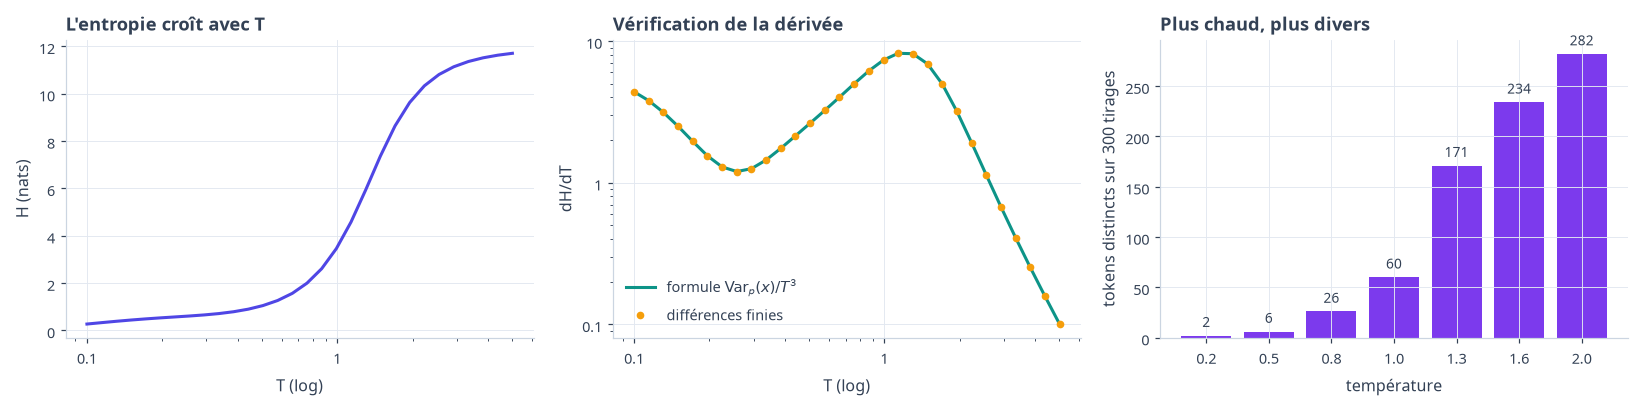

In [5]:
r8 = np.random.default_rng(8)
temps = [0.2, 0.5, 0.8, 1.0, 1.3, 1.6, 2.0]
distinct = [len(set(r8.choice(len(z), 300, p=llm.softmax(z, t)))) for t in temps]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].semilogx(Ts, H, color=INDIGO); axes[0].set_xlabel("T (log)"); axes[0].set_ylabel("H (nats)")
axes[0].set_title("L'entropie croît avec T"); m.plain_log_axis(axes[0])
axes[1].loglog(Ts, dH_th, color=TEAL, label=r"formule $\mathrm{Var}_p(x)/T^3$")
axes[1].loglog(Ts, dH_num, "o", color=AMBER, ms=4, label="différences finies")
axes[1].set_xlabel("T (log)"); axes[1].set_ylabel("dH/dT"); axes[1].legend(); axes[1].set_title("Vérification de la dérivée")
m.plain_log_axis(axes[1]); m.plain_log_axis(axes[1], "y")
axes[2].bar([str(t) for t in temps], distinct, color=VIOLET)
annotate_bars(axes[2], "{:.0f}")
axes[2].set_xlabel("température"); axes[2].set_ylabel("tokens distincts sur 300 tirages")
axes[2].set_title("Plus chaud, plus divers")
plt.tight_layout(); plt.show()

> **À retenir.** $dH/dT = \operatorname{Var}_p(x)/T^3$ : la température est un « bouton
> d'entropie » monotone, de $\log m$ (glouton) à $\log V$ (uniforme).

## Exercice 2.9 : Implémenter le top-p

**Énoncé.**

1. Écrire une fonction `mon_top_p(logits, p)` qui renvoie les logits filtrés (les autres
   à $-\infty$) en gardant le **plus petit** ensemble de tokens de probabilité cumulée
   $\ge p$. Traiter les cas limites ($p$ très petit, $p = 1$).
2. La tester contre `m.top_p_filter` sur 500 distributions aléatoires.
3. Sur un vrai texte, mesurer la taille du noyau à chaque position pour $p = 0{,}9$, et
   compter combien de fois un top-k fixe ($k = 40$) garderait des tokens de probabilité
   inférieure à $10^{-3}$.

**Rappels.** Section *Top-p* : on trie les probabilités par ordre décroissant, on cumule,
et l'on s'arrête dès que la somme atteint $p$ ; top-k garde un nombre fixe de tokens.

**Solution.** Après tri décroissant $p_{(1)} \ge p_{(2)} \ge \dots$, la taille du noyau est
$n^\star = \min\{n : \sum_{k \le n} p_{(k)} \ge p\}$ ; on garde toujours au moins le premier
token (cas $p$ très petit), et tous les tokens si $p = 1$. Une tolérance numérique évite
qu'une somme de flottants comme $0{,}5 + 0{,}3 = 0{,}7999\dots$ manque le seuil $0{,}8$.

In [6]:
def mon_top_p(logits, p):
    logits = np.asarray(logits, dtype=float)
    probs = llm.softmax(logits)
    order = np.argsort(-probs)                     # indices par probabilité décroissante
    cum = np.cumsum(probs[order])
    n = int(np.argmax(cum >= p - 1e-9)) + 1 if cum[-1] >= p - 1e-9 else len(order)
    out = np.full_like(logits, -np.inf)
    out[order[:n]] = logits[order[:n]]
    return out


ok = 0
for _ in range(500):
    zz = rng.normal(0, rng.uniform(0.5, 4), size=rng.integers(2, 200))
    pp = rng.uniform(0.01, 1.0)
    ok += np.array_equal(np.isfinite(mon_top_p(zz, pp)), np.isfinite(m.top_p_filter(zz, pp)))
z4 = np.log([0.5, 0.3, 0.15, 0.05])
print(f"accord avec m.top_p_filter : {ok}/500")
print("cas limites :", [int(np.isfinite(mon_top_p(z4, p)).sum()) for p in [1e-6, 0.5, 0.8, 0.81, 1.0]],
      "tokens gardés pour p = 1e-6, 0.5, 0.8, 0.81, 1")

accord avec m.top_p_filter : 500/500
cas limites : [1, 1, 2, 3, 4] tokens gardés pour p = 1e-6, 0.5, 0.8, 0.81, 1


In [7]:
texte = ("La recette est simple : faites fondre le beurre dans une casserole, ajoutez la farine, puis versez "
         "le lait petit à petit en remuant sans cesse jusqu'à obtenir une sauce lisse et onctueuse.")
tb, mb = llm.load(BASE_QWEN)
ids = tb(texte, return_tensors="pt")["input_ids"].to(mb.device)
with torch.no_grad():
    Z = mb(ids).logits[0, :-1].float().cpu().numpy()
nucleus = np.array([int(np.isfinite(mon_top_p(Z[t], 0.9)).sum()) for t in range(len(Z))])
junk_topk = []
for t in range(len(Z)):
    pr = llm.softmax(Z[t])
    kept = np.argsort(-pr)[:40]
    junk_topk.append(int((pr[kept] < 1e-3).sum()))
junk_topk = np.array(junk_topk)
print(f"noyau p = 0.9 : min {nucleus.min()}, médiane {int(np.median(nucleus))}, max {nucleus.max()} tokens")
print(f"top-k = 40 garde en moyenne {junk_topk.mean():.1f} tokens de probabilité < 1e-3 par position")

noyau p = 0.9 : min 1, médiane 10, max 6437 tokens
top-k = 40 garde en moyenne 14.7 tokens de probabilité < 1e-3 par position


**Vérification graphique.**

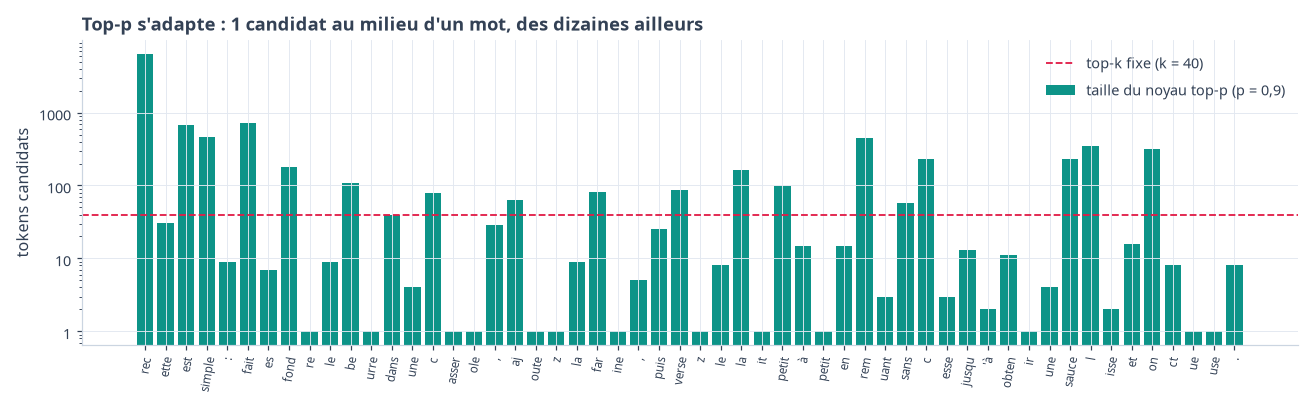

In [8]:
fig, ax = plt.subplots(figsize=(12, 3.8))
x = np.arange(len(nucleus))
ax.bar(x, nucleus, color=TEAL, label="taille du noyau top-p (p = 0,9)")
ax.axhline(40, color=ROSE, ls="--", lw=1.2, label="top-k fixe (k = 40)")
ax.set_yscale("log"); m.plain_log_axis(ax, "y")
ax.set_xticks(x, [repr(tb.decode([i]))[1:-1] for i in ids[0, 1:].tolist()], rotation=80, fontsize=7.5)
ax.set_ylabel("tokens candidats"); ax.legend(loc="upper right")
ax.set_title("Top-p s'adapte : 1 candidat au milieu d'un mot, des dizaines ailleurs")
plt.tight_layout(); plt.show()

Aux positions très prévisibles, un top-k à 40 laisse passer des dizaines de tokens quasi
impossibles (et donc, avec une température élevée, des risques d'incohérence) ; aux
positions ouvertes, il peut au contraire être trop restrictif. Le noyau top-p ajuste
automatiquement sa taille.

> **À retenir.** Le top-p se code en quelques lignes (tri, somme cumulée, seuil) ; sa
> taille adaptative explique son succès pratique face au top-k.